# Day 5 – Hourly Demand Forecasting

### Business Objective
Analyze historical order demand, identify hourly trends, and forecast the next 24 hours to support staffing and delivery resource planning.

## 1. Load Libraries
Pandas prepares the data, Matplotlib/Seaborn create plots, Statsmodels provides decomposition, ADF & ARIMA, and Prophet provides an alternative forecasting approach. 

In [64]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

try:
    from prophet import Prophet
    PROPHET_AVAILABLE = True
except ImportError:
    PROPHET_AVAILABLE = False
    print("Prophet is not installed; ARIMA sections can still run.")

print("Libraries loaded. Prophet available:", PROPHET_AVAILABLE)

Libraries loaded. Prophet available: True


## 2. Locate and Load `orders.csv`
The notebook searches the current folder and its parent folders for `data/raw/orders.csv`. If your file is elsewhere, update `DATA_PATH` manually. We inspect the columns before selecting a timestamp field.

In [65]:
project_root = None
for root in [Path.cwd(), *Path.cwd().parents]:
    if (root / "data" / "raw" / "orders.csv").exists():
        project_root = root
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not find data/raw/orders.csv. Run from the project folder or set DATA_PATH manually."
    )

DATA_PATH = project_root / "data" / "raw" / "orders.csv"
orders = pd.read_csv(DATA_PATH)
print("Project root:", project_root)
print("Shape:", orders.shape)
print("Columns:", orders.columns.tolist())
display(orders.head())

Project root: /home/nineleaps-admin/uber-eats-intelligence
Shape: (10000, 8)
Columns: ['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'number_of_items', 'order_status', 'payment_method']


,order_id,customer_id,restaurant_id,order_timestamp,order_amount,number_of_items,order_status,payment_method
0,100001,1891,74,2025-11-14 22:14:00,165.09,2,Completed,UPI
1,100002,1669,20,2025-11-13 00:39:00,369.44,4,Completed,UPI
2,100003,107,54,2025-01-04 01:42:00,349.26,7,Completed,UPI
3,100004,307,69,2025-09-05 16:56:00,379.08,7,Completed,Card
4,100005,800,20,2025-12-28 17:57:00,1343.82,7,Completed,Card


### Observation — Dataset inspection
The orders dataset comprises 10,000 rows across 8 columns, with the `order_timestamp` column successfully identified. Spanning January 1, 2025 to December 31, 2025, all 10,000 records contained valid timestamps, resulting in zero rows removed during the timestamp cleaning process.

## 3. Identify and Prepare the Timestamp
Hourly forecasting requires an order timestamp. The code checks common column names. If none is found, it stops so you can set `TIMESTAMP_COLUMN` to the correct field from the dataset.

In [66]:
TIMESTAMP_COLUMN = None  # If needed, set this to the exact timestamp column name.

timestamp_candidates = [
    "order_time", "order_timestamp", "order_datetime", "created_at",
    "order_date", "timestamp", "date_time", "datetime"
]
if TIMESTAMP_COLUMN is None:
    columns_lower = {col.lower(): col for col in orders.columns}
    for candidate in timestamp_candidates:
        if candidate in columns_lower:
            TIMESTAMP_COLUMN = columns_lower[candidate]
            break

if TIMESTAMP_COLUMN is None:
    raise ValueError("Timestamp column not detected. Set TIMESTAMP_COLUMN manually.")

orders[TIMESTAMP_COLUMN] = pd.to_datetime(orders[TIMESTAMP_COLUMN], errors="coerce")
invalid_timestamps = orders[TIMESTAMP_COLUMN].isna().sum()
orders = orders.dropna(subset=[TIMESTAMP_COLUMN]).copy()
orders = orders.sort_values(TIMESTAMP_COLUMN)
print("Timestamp column:", TIMESTAMP_COLUMN)
print("Invalid/missing timestamps removed:", invalid_timestamps)
print("Rows retained:", len(orders))
print("Date range:", orders[TIMESTAMP_COLUMN].min(), "to", orders[TIMESTAMP_COLUMN].max())

Timestamp column: order_timestamp
Invalid/missing timestamps removed: 0
Rows retained: 10000
Date range: 2025-01-01 00:06:00 to 2025-12-31 23:32:00


## 4. Aggregate Orders into Hourly Demand
We count order records in each hour. `ds` is the timestamp and `y` is the order count; Prophet expects these column names. Missing hourly timestamps are filled with zero, assuming an absent hour means no orders were recorded.

In [67]:
hourly_demand = (
    orders.set_index(TIMESTAMP_COLUMN)
    .resample("h")
    .size()
    .rename("y")
    .reset_index()
    .rename(columns={TIMESTAMP_COLUMN: "ds"})
)
hourly_demand = (
    hourly_demand.set_index("ds")
    .asfreq("h", fill_value=0)
    .rename_axis("ds")
    .reset_index()
)
hourly_demand["y"] = hourly_demand["y"].astype(int)

print("Hourly dataset shape:", hourly_demand.shape)
print("First hour:", hourly_demand["ds"].min())
print("Last hour:", hourly_demand["ds"].max())
print("Missing values:\n", hourly_demand.isna().sum())
display(hourly_demand.head())

Hourly dataset shape: (8760, 2)
First hour: 2025-01-01 00:00:00
Last hour: 2025-12-31 23:00:00
Missing values:
 ds    0
y     0
dtype: int64


,ds,y
0,2025-01-01 00:00:00,2
1,2025-01-01 01:00:00,2
2,2025-01-01 02:00:00,2
3,2025-01-01 03:00:00,2
4,2025-01-01 04:00:00,1


### Observation — Hourly dataset
The dataset was aggregated into 8,760 continuous hourly observations for 2025, containing ds timestamp and y order-count columns. After aggregating and imputing missing timestamps, no gaps remained..

## 5. Demand Summary
Summary statistics help us understand typical hourly demand, variation, and how frequently the series contains zero-order hours.

In [68]:
display(hourly_demand["y"].describe().to_frame("hourly_order_count"))
zero_hours = int((hourly_demand["y"] == 0).sum())
print("Hours with zero orders:", zero_hours)
print("Percentage of zero-order hours:", round((hourly_demand["y"] == 0).mean() * 100, 2), "%")

,hourly_order_count
count,8760.000000
mean,1.141553
std,1.054323
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,6.000000


Hours with zero orders: 2754
Percentage of zero-order hours: 31.44 %


### Observation - Demand Summary
- Average hourly demand was approximately 1.14 orders.
- The median was 1 order per hour.
- Hourly demand ranged from 0 to 6 orders.
- A total of 2,754 hours had zero recorded orders, representing 31.44% of the hourly observations.

## 6. Hourly Demand Over Time
This time plot helps us inspect broad trends, repeated peaks, unusual spikes, and quieter periods.

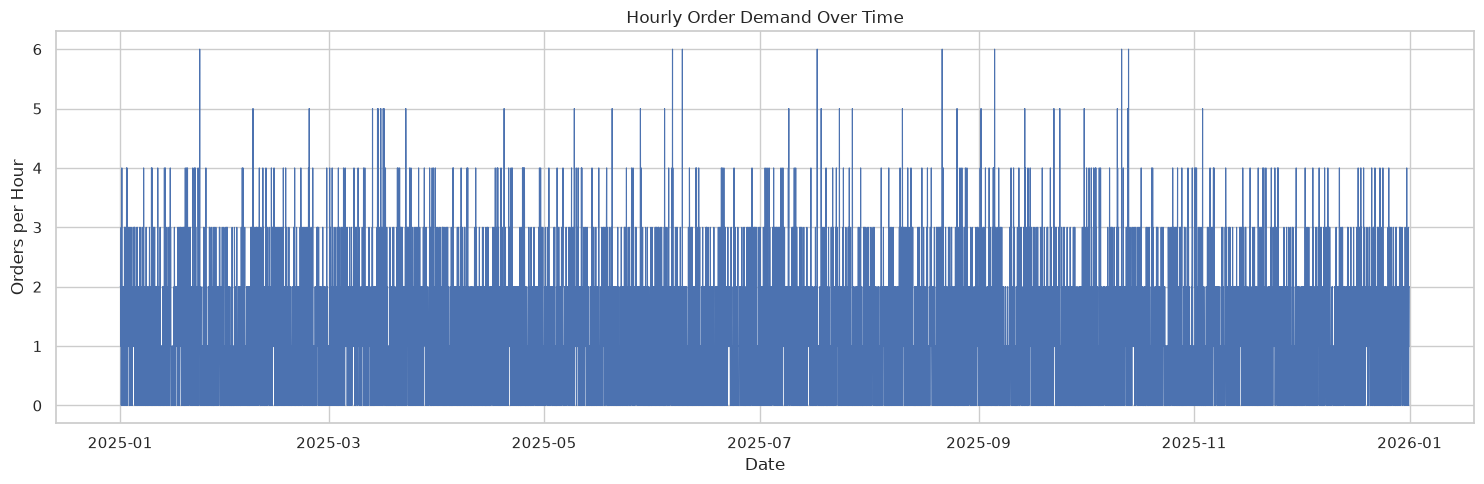

In [69]:
plt.figure(figsize=(15, 5))
plt.plot(hourly_demand["ds"], hourly_demand["y"], linewidth=0.8)
plt.title("Hourly Order Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Orders per Hour")
plt.tight_layout()
plt.show()

### Observation — Overall trend
The hourly demand plot shows frequent fluctuations throughout the year, with occasional peaks reaching approximately 6 orders per hour. Demand generally remains within a relatively low range, and there is no clearly established long-term upward or downward trend from the plot.

## 7. Hour-of-Day Pattern
We calculate average order counts for each hour across the available history. This helps identify the busiest and quietest hours in the generated dataset.

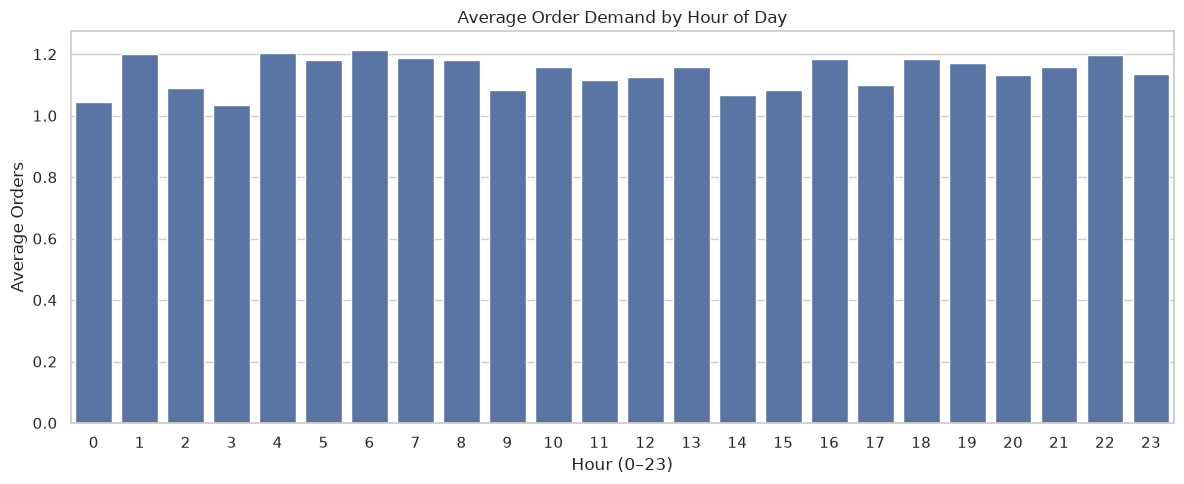

,hour,average_orders
6,6,1.213699
4,4,1.205479
1,1,1.200000
22,22,1.197260
7,7,1.189041


In [70]:
hourly_demand["hour"] = hourly_demand["ds"].dt.hour
hourly_demand["day_of_week"] = hourly_demand["ds"].dt.dayofweek
hourly_demand["day_name"] = hourly_demand["ds"].dt.day_name()
hourly_demand["is_weekend"] = hourly_demand["day_of_week"] >= 5

hour_pattern = hourly_demand.groupby("hour", as_index=False)["y"].mean()
plt.figure(figsize=(12, 5))
sns.barplot(data=hour_pattern, x="hour", y="y")
plt.title("Average Order Demand by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Average Orders")
plt.tight_layout()
plt.show()
display(hour_pattern.sort_values("y", ascending=False).head(5).rename(columns={"y": "average_orders"}))

### Observation — Hourly peaks
- 6 AM recorded the highest average demand, at approximately 1.21 orders per hour.
- Other relatively high-demand hours included 4 AM, 1 AM, 10 PM, and 7 AM.
- Average demand across the hours of the day remained relatively close, with no pronounced lunch or dinner peak.

## 8. Day-of-Week and Weekend Patterns
This section compares average hourly demand across days and between weekdays and weekends. These are descriptive patterns, not proof that day type causes demand to change.

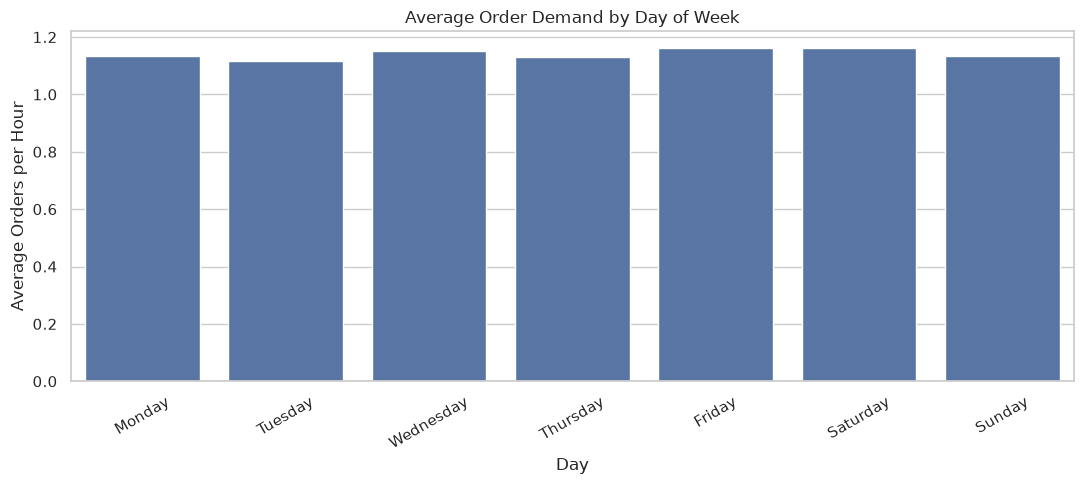

,day_name,average_orders
0,Monday,1.135417
1,Tuesday,1.115385
2,Wednesday,1.150157
3,Thursday,1.132212
4,Friday,1.161859
5,Saturday,1.161058
6,Sunday,1.134615


,day_type,average_orders
0,Weekday,1.139049
1,Weekend,1.147837


In [71]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_pattern = (
    hourly_demand.groupby("day_name")["y"].mean()
    .reindex(day_order)
    .rename("average_orders")
    .reset_index()
)

plt.figure(figsize=(11, 5))
sns.barplot(data=day_pattern, x="day_name", y="average_orders", order=day_order)
plt.title("Average Order Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Orders per Hour")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

weekend_pattern = (
    hourly_demand.groupby("is_weekend")["y"].mean()
    .rename(index={False: "Weekday", True: "Weekend"})
    .rename("average_orders")
    .reset_index()
)

weekend_pattern.columns = ["day_type", "average_orders"]

display(day_pattern)
display(weekend_pattern)

### Observation — Weekly pattern
- Friday had the highest average demand, at approximately 1.162 orders per hour.
- Tuesday had the lowest average demand, at approximately 1.115 orders per hour.
- Weekends averaged 1.148 orders per hour, compared with 1.139 on weekdays.

## 9. Hour-by-Day Heatmap
The heatmap combines hour-of-day and day-of-week averages. It can reveal whether peak hours differ across weekdays and weekends.

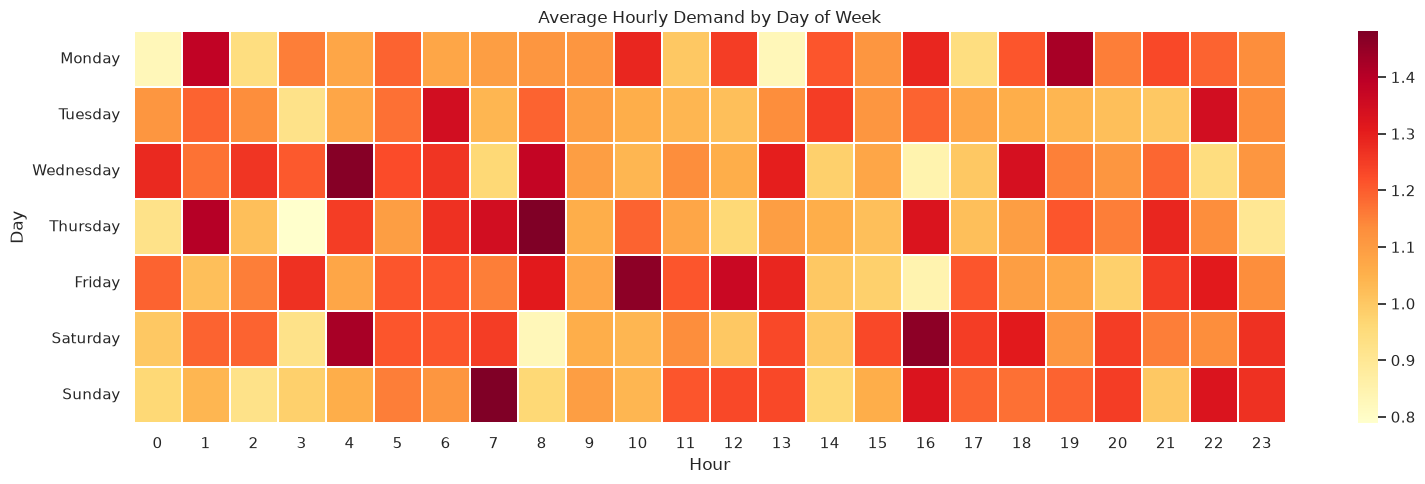

In [72]:
heatmap_data = hourly_demand.pivot_table(
    index="day_name", columns="hour", values="y", aggfunc="mean"
).reindex(day_order)
plt.figure(figsize=(16, 5))
sns.heatmap(heatmap_data, cmap="YlOrRd", linewidths=0.2)
plt.title("Average Hourly Demand by Day of Week")
plt.xlabel("Hour")
plt.ylabel("Day")
plt.tight_layout()
plt.show()

## 10. Time-Series Decomposition
Decomposition separates the series into estimated trend, seasonality, and residual components. We start with a 24-hour period to investigate daily repetition. It needs multiple complete cycles, and results should be interpreted cautiously if the dataset is short or irregular.

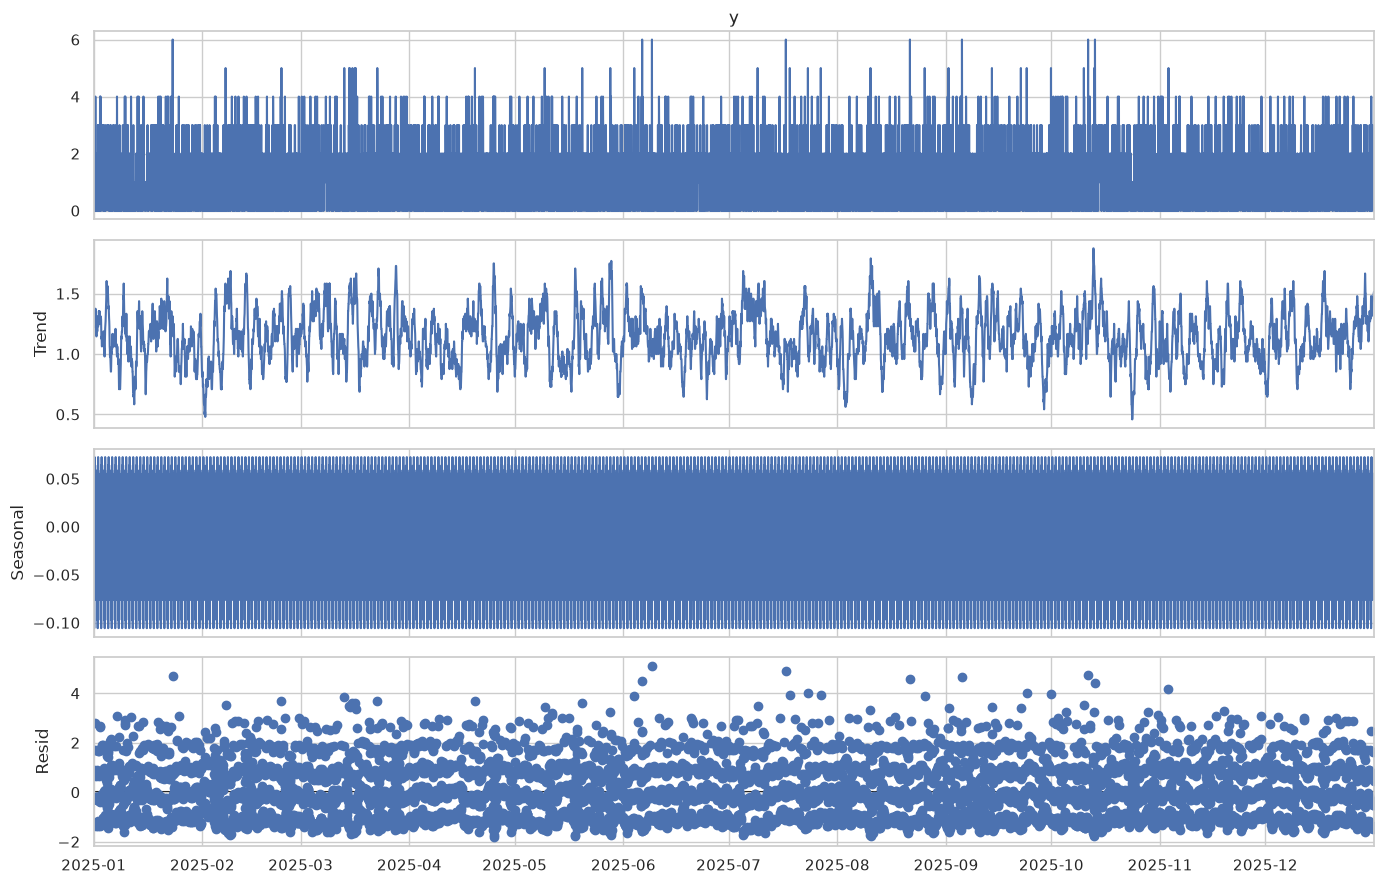

In [73]:
SEASONAL_PERIOD = 24
if len(hourly_demand) < 2 * SEASONAL_PERIOD:
    print("Not enough hourly observations for 24-hour decomposition.")
else:
    decomposition = seasonal_decompose(
        hourly_demand.set_index("ds")["y"],
        model="additive",
        period=SEASONAL_PERIOD,
        extrapolate_trend="freq"
    )
    fig = decomposition.plot()
    fig.set_size_inches(14, 9)
    plt.tight_layout()
    plt.show()

### Observation — Decomposition
The decomposition separates hourly demand into observed, trend, seasonal, and residual components:

* **Trend:** Fluctuates near a stable baseline with no distinct long-term drift.
* **Seasonal:** Shows recurring patterns, but EDA reveals no definitive daily cycle.
* **Residual:** Exhibits high irregularity, substantial hourly variance is unexplained.

## 11. Stationarity and the ADF Test
The Augmented Dickey-Fuller (ADF), a diagnostic test evaluates the null hypothesis that the series has a unit root.
- **p-value < 0.05:** Reject the unit-root null; this is evidence in favor of stationarity under the test assumptions.
- **p-value ≥ 0.05:** Fail to reject the null; the test has not established stationarity.

In [74]:
def run_adf(series, label):
    result = adfuller(pd.Series(series).dropna(), autolag="AIC")
    row = {
        "series": label,
        "adf_statistic": result[0],
        "p_value": result[1],
        "used_lags": result[2],
        "observations": result[3],
        "critical_value_1%": result[4]["1%"],
        "critical_value_5%": result[4]["5%"],
        "critical_value_10%": result[4]["10%"]
    }
    display(pd.DataFrame([row]).round(4))
    print("Reject unit-root null at 5%:", result[1] < 0.05)
    return result

adf_original = run_adf(hourly_demand["y"], "Original hourly demand")

,series,adf_statistic,p_value,used_lags,observations,critical_value_1%,critical_value_5%,critical_value_10%
0,Original hourly demand,-35.5287,0.0,6,8753,-3.4311,-2.8619,-2.5669


Reject unit-root null at 5%: True


### Conclusion - ADF Test
We reject the unit-root null hypothesis at the 5% significance level. The test provides strong evidence that the original hourly demand series is stationary under the ADF test's assumptions.

## 12. Differencing and Rechecking Stationarity
Differencing calculates the change between consecutive observations. We test first differences as a diagnostic; the ARIMA model's differencing order is configured separately.

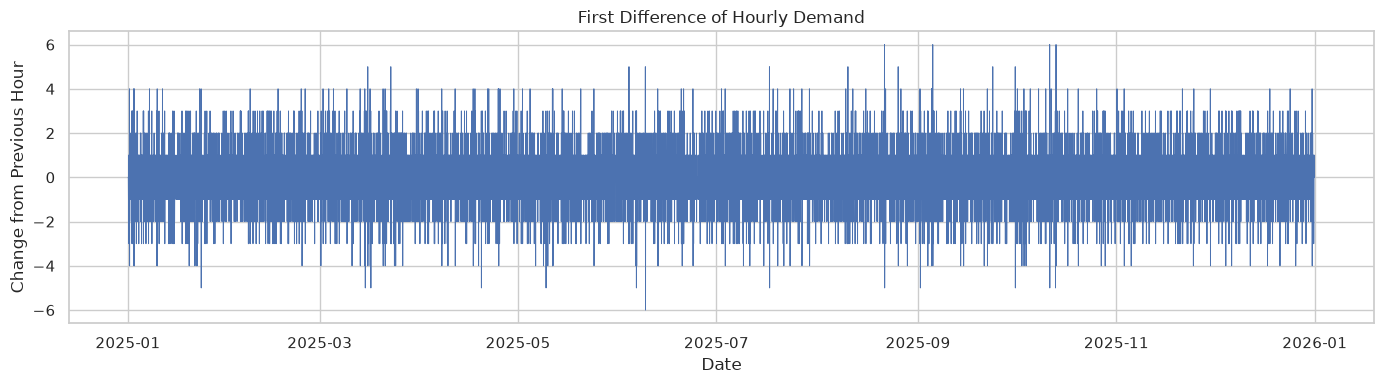

,series,adf_statistic,p_value,used_lags,observations,critical_value_1%,critical_value_5%,critical_value_10%
0,First-differenced demand,-26.5195,0.0,36,8722,-3.4311,-2.8619,-2.5669


Reject unit-root null at 5%: True


In [75]:
hourly_demand["y_diff_1"] = hourly_demand["y"].diff()
plt.figure(figsize=(14, 4))
plt.plot(hourly_demand["ds"], hourly_demand["y_diff_1"], linewidth=0.7)
plt.title("First Difference of Hourly Demand")
plt.xlabel("Date")
plt.ylabel("Change from Previous Hour")
plt.tight_layout()
plt.show()

adf_differenced = run_adf(hourly_demand["y_diff_1"], "First-differenced demand")

### Observation — Stationarity
The differenced series also shows strong evidence of stationarity.
Since the original series already passed the ADF test, differencing was not strictly required and should be guided by model diagnostics rather than applied automatically.

## 13. Chronological Train/Test Split
We use the first 80% of observations for training and the final 20% for testing. Both models will be evaluated against the same test period.

In [76]:
model_data = hourly_demand[["ds", "y"]].copy().sort_values("ds").reset_index(drop=True)
split_index = int(len(model_data) * 0.80)
if split_index < 48 or len(model_data) - split_index < 1:
    raise ValueError("Dataset is too short for this 80/20 hourly train/test split.")

train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()
print("Training rows:", len(train), "| Testing rows:", len(test))
print("Training period:", train["ds"].min(), "to", train["ds"].max())
print("Testing period:", test["ds"].min(), "to", test["ds"].max())
print("Chronological split valid:", train["ds"].max() < test["ds"].min())

Training rows: 7008 | Testing rows: 1752
Training period: 2025-01-01 00:00:00 to 2025-10-19 23:00:00
Testing period: 2025-10-20 00:00:00 to 2025-12-31 23:00:00
Chronological split valid: True


## 14. Forecast Evaluation Metrics
- **MAE:** Average absolute error, measured in orders per hour.
- **RMSE:** Penalizes larger errors more heavily.
- **MAPE:** To prevent division by zero, MAPE is computed only across non-zero test observations, with the included count reported alongside it.

Lower values are better for all three metrics.

In [77]:
def evaluate_forecast(actual, predicted, model_name):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = actual != 0
    mape = (
        np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )
    return {
        "model": model_name,
        "MAE_orders_per_hour": mae,
        "RMSE_orders_per_hour": rmse,
        "MAPE_nonzero_actual_%": mape,
        "observations_for_MAPE": int(nonzero.sum()),
        "test_observations": len(actual)
    }

## 15. ARIMA Forecasting
We start with ARIMA(1, 1, 1) as a simple baseline configuration, not a claim that this is the optimal order. The model is fitted only on training observations and forecasts the held-out test period.

In [78]:
arima_order = (1, 1, 1)
arima_fit = None
arima_predictions = None
arima_results = None

try:
    arima_fit = ARIMA(train["y"], order=arima_order).fit()
    arima_predictions = np.asarray(arima_fit.forecast(steps=len(test)), dtype=float)
    arima_results = evaluate_forecast(test["y"], arima_predictions, f"ARIMA{arima_order}")
    display(pd.DataFrame([arima_results]).round(3))
    print(arima_fit.summary())
except Exception as exc:
    print("ARIMA fitting failed:", repr(exc))

,model,MAE_orders_per_hour,RMSE_orders_per_hour,MAPE_nonzero_actual_%,observations_for_MAPE,test_observations
0,"ARIMA(1, 1, 1)",0.798,1.016,30.132,1209,1752


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 7008
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -10379.778
Date:                Thu, 29 Oct 2026   AIC                          20765.556
Time:                        12:26:10   BIC                          20786.120
Sample:                             0   HQIC                         20772.642
                               - 7008                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0050      0.012      0.411      0.681      -0.019       0.029
ma.L1         -0.9999      0.006   -156.966      0.000      -1.012      -0.987
sigma2         1.1315      0.018     63.198      0.0

### ARIMA forecast plot
Compare actual test demand with the ARIMA forecast. The test observations are for evaluation only and were not used to fit the model.

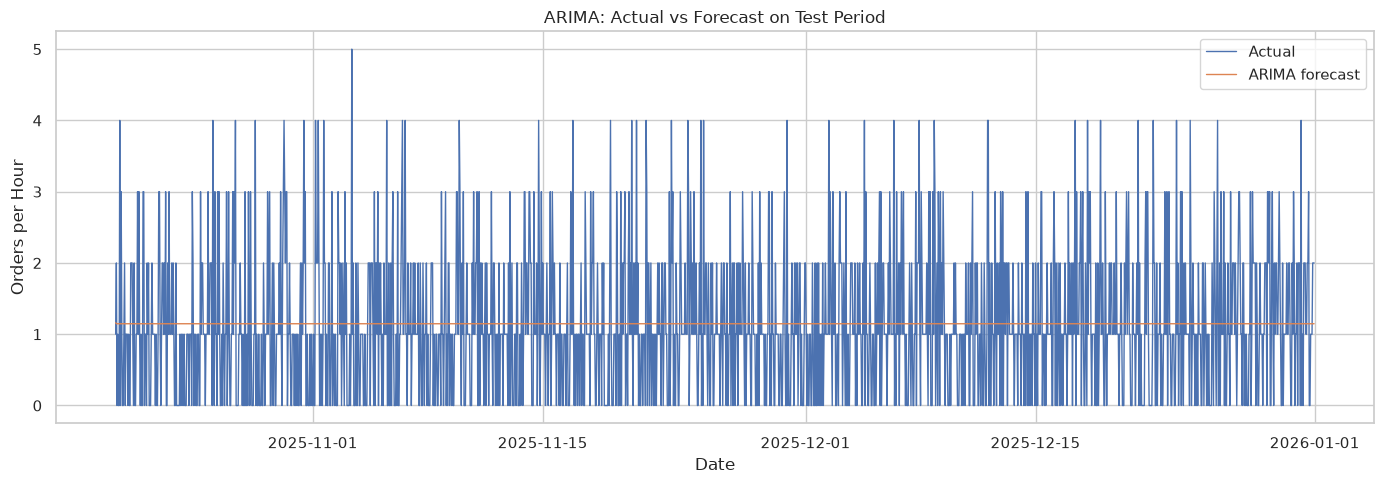

In [79]:
if arima_predictions is not None:
    plt.figure(figsize=(14, 5))
    plt.plot(test["ds"], test["y"], label="Actual", linewidth=1)
    plt.plot(test["ds"], arima_predictions, label="ARIMA forecast", linewidth=1)
    plt.title("ARIMA: Actual vs Forecast on Test Period")
    plt.xlabel("Date")
    plt.ylabel("Orders per Hour")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Observation — ARIMA
The model achieved an MAE of approximately 0.8 orders per hour, the forecast plot reveals it generates relatively smooth predictions that smooth over the frequent fluctuations in actual demand.

ARIMA serves as a reasonable baseline with an error below one order per hour, but its smooth trajectory limits its ability to capture sharp, short-term demand swings.

## 16. Prophet Forecasting
Prophet uses `ds` and `y` columns. It is trained only on the training period and predicts the test timestamps. 

In [80]:
prophet_results = None
prophet_predictions = None
prophet_model = None
prophet_forecast = None

if not PROPHET_AVAILABLE:
    print("Skipping Prophet: install prophet in your environment and rerun this section.")
else:
    try:
        train_span_days = (train["ds"].max() - train["ds"].min()).total_seconds() / 86400
        yearly_enabled = train_span_days >= 730
        prophet_model = Prophet(
            daily_seasonality=True,
            weekly_seasonality=True,
            yearly_seasonality=yearly_enabled,
            interval_width=0.80
        )
        prophet_model.fit(train[["ds", "y"]])
        prophet_forecast = prophet_model.predict(test[["ds"]].copy())
        prophet_predictions = prophet_forecast["yhat"].to_numpy(dtype=float)
        prophet_results = evaluate_forecast(test["y"], prophet_predictions, "Prophet")
        display(pd.DataFrame([prophet_results]).round(3))
        print("Yearly seasonality enabled:", yearly_enabled)
    except Exception as exc:
        prophet_model = None
        prophet_predictions = None
        prophet_results = None
        print("Prophet fitting failed:", repr(exc))

12:26:11 - cmdstanpy - INFO - Chain [1] start processing
12:26:12 - cmdstanpy - INFO - Chain [1] done processing


,model,MAE_orders_per_hour,RMSE_orders_per_hour,MAPE_nonzero_actual_%,observations_for_MAPE,test_observations
0,Prophet,0.8,1.018,30.32,1209,1752


Yearly seasonality enabled: False


### Prophet forecast plot
Compare actual test demand with Prophet's prediction. The shaded band represents its estimated 80% uncertainty interval.


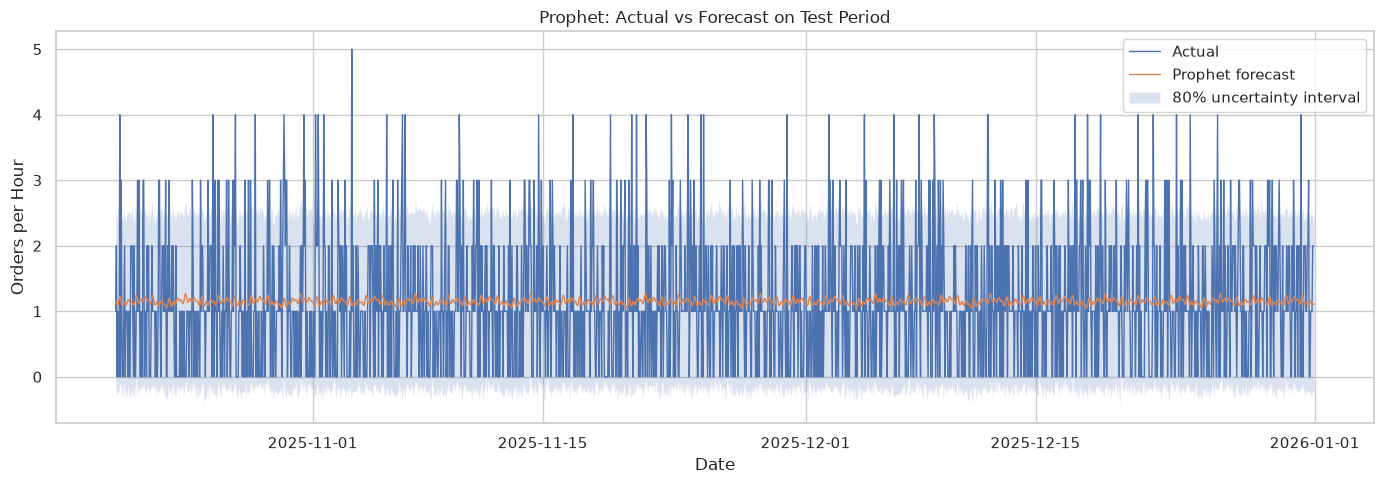

In [81]:
if prophet_forecast is not None:
    plt.figure(figsize=(14, 5))
    plt.plot(test["ds"], test["y"], label="Actual", linewidth=1)
    plt.plot(test["ds"], prophet_forecast["yhat"], label="Prophet forecast", linewidth=1)
    plt.fill_between(
        test["ds"], prophet_forecast["yhat_lower"], prophet_forecast["yhat_upper"],
        alpha=0.2, label="80% uncertainty interval"
    )
    plt.title("Prophet: Actual vs Forecast on Test Period")
    plt.xlabel("Date")
    plt.ylabel("Orders per Hour")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Observation checkpoint — Prophet
Prophet was fitted with daily and weekly seasonality enabled—disabling yearly effects due to the sub-two-year timeframe—producing a forecast line that runs notably smoother than the observed hourly demand swings.

Prophet provides reasonable forecasts with error metrics only marginally higher than ARIMA, indicating not much performance difference between the two models.

## 17. Compare ARIMA and Prophet
We compare models using the same test period. The lowest-error model performs best on this holdout, but one test split does not guarantee it will always perform better.

In [82]:
results_list = [r for r in [arima_results, prophet_results] if r is not None]
if results_list:
    model_comparison = pd.DataFrame(results_list).sort_values("MAE_orders_per_hour")
    display(model_comparison.round(3))
    best_model_name = model_comparison.iloc[0]["model"]
    print("Lowest test MAE:", best_model_name)
else:
    model_comparison = pd.DataFrame()
    print("No model results available; review the model fitting messages.")

,model,MAE_orders_per_hour,RMSE_orders_per_hour,MAPE_nonzero_actual_%,observations_for_MAPE,test_observations
0,"ARIMA(1, 1, 1)",0.798,1.016,30.132,1209,1752
1,Prophet,0.800,1.018,30.320,1209,1752


Lowest test MAE: ARIMA(1, 1, 1)


### Observation — Model comparison
ARIMA(1, 1, 1) performed best across test metrics, but due to the minimal margin it cannot be considered substantially superior to Prophet.

## 18. Prophet Components
Prophet component plots help show how the fitted model represents trend and seasonality. 

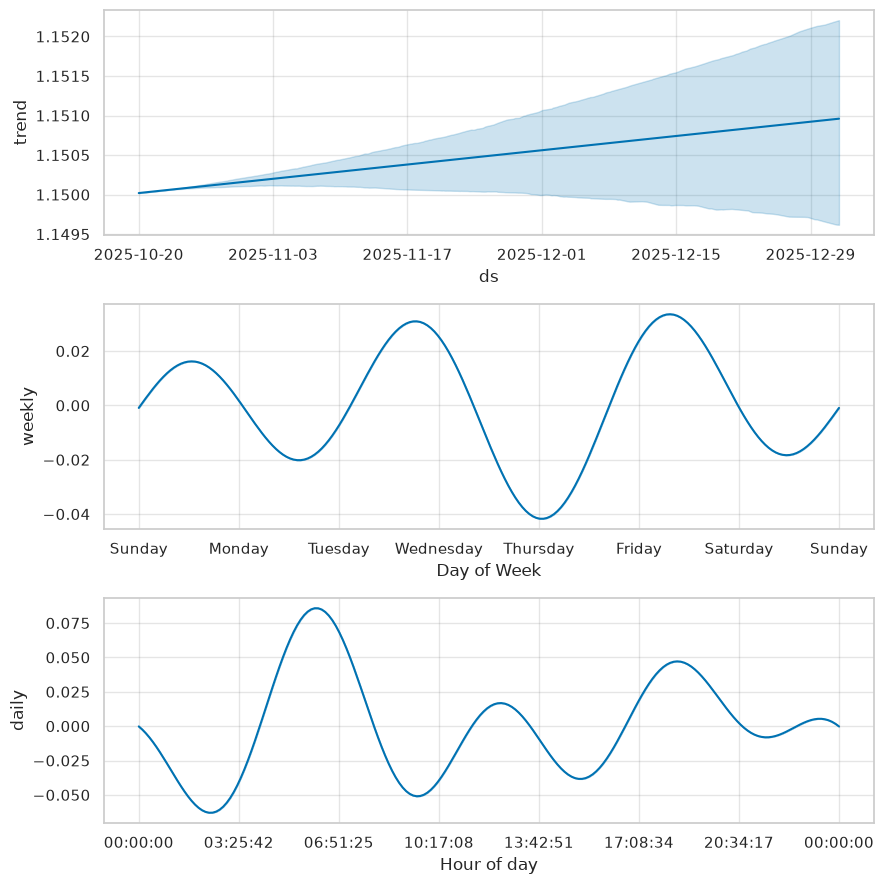

In [83]:
if prophet_model is not None and prophet_forecast is not None:
    prophet_model.plot_components(prophet_forecast)
    plt.tight_layout()
    plt.show()
else:
    print("Prophet component plots unavailable because Prophet was not fitted.")

## 19. Forecast the Next 24 Hours
ARIMA was selected to generate the final forecast because it achieved the lowest test MAE.


In [84]:
FORECAST_HOURS = 24
final_forecast = None

if not results_list:
    print("Cannot create a final forecast because no model fitted successfully.")
else:
    full_data = model_data[["ds", "y"]].copy()
    future_dates = pd.date_range(
        start=full_data["ds"].max() + pd.Timedelta(hours=1),
        periods=FORECAST_HOURS, freq="h"
    )

    if best_model_name.startswith("ARIMA"):
        final_fit = ARIMA(full_data["y"], order=arima_order).fit()
        raw_values = np.asarray(final_fit.forecast(steps=FORECAST_HOURS), dtype=float)
        final_forecast = pd.DataFrame({"ds": future_dates, "forecast_orders_raw": raw_values})

    elif best_model_name == "Prophet" and PROPHET_AVAILABLE:
        full_span_days = (full_data["ds"].max() - full_data["ds"].min()).total_seconds() / 86400
        final_fit = Prophet(
            daily_seasonality=True,
            weekly_seasonality=True,
            yearly_seasonality=full_span_days >= 730,
            interval_width=0.80
        )
        final_fit.fit(full_data)
        future_output = final_fit.predict(pd.DataFrame({"ds": future_dates}))
        final_forecast = pd.DataFrame({
            "ds": future_dates,
            "forecast_orders_raw": future_output["yhat"].to_numpy(),
            "lower_bound": future_output["yhat_lower"].to_numpy(),
            "upper_bound": future_output["yhat_upper"].to_numpy()
        })

    if final_forecast is not None:
        final_forecast["forecast_orders"] = (
            final_forecast["forecast_orders_raw"].clip(lower=0).round().astype(int)
        )
        print("Selected model:", best_model_name)
        display(final_forecast.round(2))

Selected model: ARIMA(1, 1, 1)


,ds,forecast_orders_raw,forecast_orders
0,2026-01-01 00:00:00,1.15,1
1,2026-01-01 01:00:00,1.14,1
2,2026-01-01 02:00:00,1.14,1
3,2026-01-01 03:00:00,1.14,1
4,2026-01-01 04:00:00,1.14,1
5,2026-01-01 05:00:00,1.14,1
6,2026-01-01 06:00:00,1.14,1
7,2026-01-01 07:00:00,1.14,1
8,2026-01-01 08:00:00,1.14,1
9,2026-01-01 09:00:00,1.14,1


### Final forecast plot
The chart compares recent historical demand with the forecast for the next 24 hours.

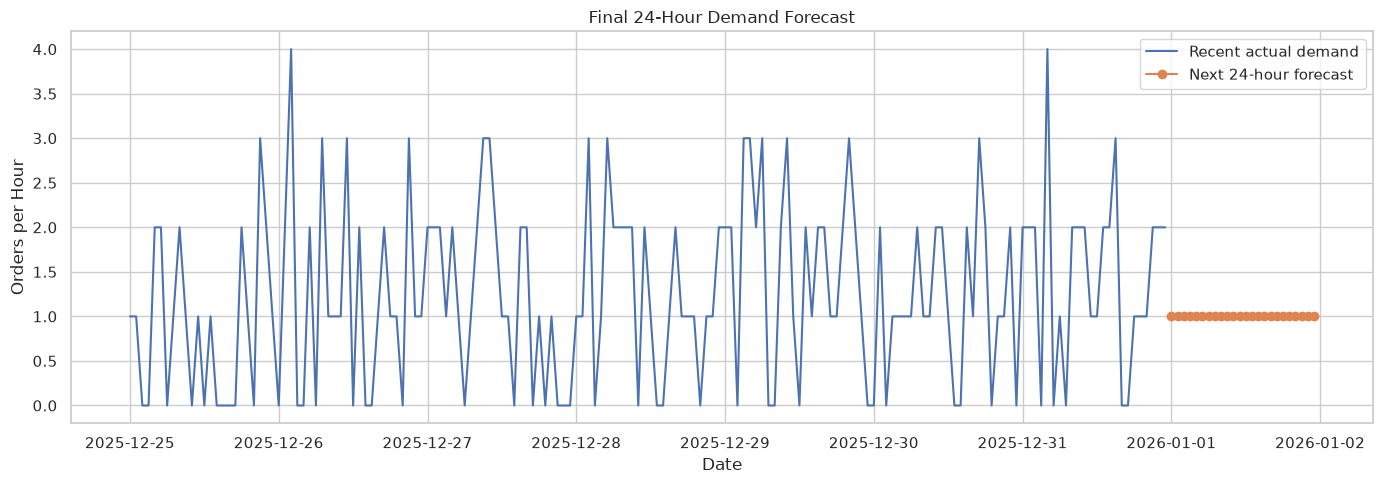

In [85]:
if final_forecast is not None:
    recent = hourly_demand.tail(7 * 24)
    plt.figure(figsize=(14, 5))
    plt.plot(recent["ds"], recent["y"], label="Recent actual demand")
    plt.plot(final_forecast["ds"], final_forecast["forecast_orders"],
             label="Next 24-hour forecast", marker="o")
    if {"lower_bound", "upper_bound"}.issubset(final_forecast.columns):
        plt.fill_between(
            final_forecast["ds"], final_forecast["lower_bound"], final_forecast["upper_bound"],
            alpha=0.2, label="Prophet uncertainty interval"
        )
    plt.title("Final 24-Hour Demand Forecast")
    plt.xlabel("Date")
    plt.ylabel("Orders per Hour")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Final forecast unavailable.")

### Observation - Forecasting
- The forecast predicts approximately 1.14 orders per hour. After rounding, it becomes 1 order per hour.

- The forecast appears flat because the synthetic dataset has low hourly demand and weak, inconsistent patterns, causing the models to predict values close to the average.

- A similar flat forecast was observed with SARIMA using the 90:10 split, suggesting the pattern is related to the dataset's characteristics rather than a single model or split ratio.

## 20. Save Main Outputs


In [86]:
output_dir = project_root / "reports" / "day5_hourly_forecasting"
output_dir.mkdir(parents=True, exist_ok=True)
hourly_demand[["ds", "y"]].to_csv(output_dir / "hourly_demand.csv", index=False)
if not model_comparison.empty:
    model_comparison.to_csv(output_dir / "model_comparison.csv", index=False)
if final_forecast is not None:
    final_forecast.to_csv(output_dir / "next_24_hour_forecast.csv", index=False)
print("Outputs saved to:", output_dir)

Outputs saved to: /home/nineleaps-admin/uber-eats-intelligence/reports/day5_hourly_forecasting


## 21. Final Business Insights

- Demand Patterns: Average demand was 1.14 orders per hour, with 31.44% of hours recording zero orders.

- Hourly and Weekly Trends: Friday and Saturday had slightly higher demand, with no strong meal-time peaks.

- Stationarity: The ADF test confirmed that the original hourly demand series was stationary.

- Model Comparison: ARIMA slightly outperformed Prophet, achieving an MAE of 0.798 and RMSE of 1.016.

- Demand Forecast: ARIMA predicted approximately 1.14 orders per hour, reflecting stable average demand rather than hourly fluctuations.